In [5]:

from sklearn.datasets import load_iris

iris = load_iris()

print("Broj uzoraka:", len(iris.data))
print("Broj karakteristika:", len(iris.feature_names))
print("Vrste cvijeća:", iris.target_names)


Broj uzoraka: 150
Broj karakteristika: 4
Vrste cvijeća: ['setosa' 'versicolor' 'virginica']


In [6]:

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

# Factory - kreiranje modela prema nazivu
def kreiraj_model(naziv):
    modeli = {
        "linearni": LogisticRegression(max_iter=200),
        "stablo": DecisionTreeClassifier(random_state=42),
        "knn": KNeighborsClassifier()
    }

    if naziv not in modeli:
        raise ValueError("Nepoznat model")

    return modeli[naziv]


In [7]:

model = kreiraj_model("stablo")
print(model)


DecisionTreeClassifier(random_state=42)


In [8]:

from sklearn.metrics import accuracy_score, f1_score

# Strategy - izbor metrike
def tacnost(y_tacno, y_pred):
    return accuracy_score(y_tacno, y_pred)

def f1_metrika(y_tacno, y_pred):
    return f1_score(y_tacno, y_pred, average="macro")

metrike = {
    "accuracy": tacnost,
    "f1": f1_metrika
}

def izracunaj_metriku(naziv, y_tacno, y_pred):
    return metrike[naziv](y_tacno, y_pred)


In [9]:

y_tacno = [0, 1, 2, 0, 1]
y_pred = [0, 1, 1, 0, 2]

print("Accuracy:", izracunaj_metriku("accuracy", y_tacno, y_pred))
print("F1:", round(izracunaj_metriku("f1", y_tacno, y_pred), 2))


Accuracy: 0.6
F1: 0.5


In [10]:

class PracenjeTreninga:
    def kraj_treninga(self, naziv_modela):
        print("Zavrseno treniranje modela:", naziv_modela)


In [11]:

pracenje = PracenjeTreninga()

pracenje.kraj_treninga("stablo")


Zavrseno treniranje modela: stablo


In [12]:

class Treniranje:
    def __init__(self):
        self.pratioci = []

    def dodaj_pratioca(self, pratilac):
        self.pratioci.append(pratilac)

    def treniraj(self, model, x, y):
        model.fit(x, y)

        for pratilac in self.pratioci:
            pratilac.kraj_treninga(type(model).__name__)

        return model


In [13]:

trening = Treniranje()
trening.dodaj_pratioca(PracenjeTreninga())

model = kreiraj_model("stablo")

trening.treniraj(model, iris.data, iris.target)


Zavrseno treniranje modela: DecisionTreeClassifier


DecisionTreeClassifier(random_state=42)

In [14]:

class Eksperiment:
    def pokreni(self):
        x, y = self.ucitaj_podatke()
        model = self.napravi_model()
        model.fit(x, y)
        rezultat = self.provjeri_model(model, x, y)
        return rezultat

    def ucitaj_podatke(self):
        return iris.data, iris.target

    def napravi_model(self):
        return kreiraj_model("stablo")

    def provjeri_model(self, model, x, y):
        predvidjanja = model.predict(x)
        return izracunaj_metriku("accuracy", y, predvidjanja)


In [15]:

eksperiment = Eksperiment()

rezultat = eksperiment.pokreni()

print("Tacnost modela:", rezultat)


Tacnost modela: 1.0


In [16]:

class KNNEksperiment(Eksperiment):
    def napravi_model(self):
        return kreiraj_model("knn")


In [17]:

knn_eksperiment = KNNEksperiment()

rezultat = knn_eksperiment.pokreni()

print("Tacnost KNN modela:", rezultat)


Tacnost KNN modela: 0.9666666666666667


In [18]:

import time
from functools import wraps

def mjeri_vrijeme(funkcija):
    @wraps(funkcija)
    def nova_funkcija(*args, **kwargs):
        pocetak = time.time()
        rezultat = funkcija(*args, **kwargs)
        kraj = time.time()

        print("Vrijeme izvrsavanja:", round(kraj - pocetak, 4), "sekundi")
        return rezultat

    return nova_funkcija


In [19]:

class EksperimentSaVremenom(Eksperiment):
    @mjeri_vrijeme
    def pokreni(self):
        return super().pokreni()


In [20]:

eksperiment = EksperimentSaVremenom()

rezultat = eksperiment.pokreni()

print("Tacnost modela:", rezultat)


Vrijeme izvrsavanja: 0.004 sekundi
Tacnost modela: 1.0


In [21]:

from sklearn.model_selection import train_test_split

x_trening, x_test, y_trening, y_test = train_test_split(
    iris.data,
    iris.target,
    test_size=0.2,
    random_state=42,
    stratify=iris.target
)

print("Podaci za treniranje:", len(x_trening))
print("Podaci za testiranje:", len(x_test))


Podaci za treniranje: 120
Podaci za testiranje: 30


In [22]:

class Eksperiment:
    def pokreni(self):
        x_trening, x_test, y_trening, y_test = train_test_split(
            iris.data, iris.target,
            test_size=0.2,
            random_state=42,
            stratify=iris.target
        )

        model = self.napravi_model()

        trening = Treniranje()
        trening.dodaj_pratioca(PracenjeTreninga())
        trening.treniraj(model, x_trening, y_trening)

        predvidjanja = model.predict(x_test)
        rezultat = izracunaj_metriku("accuracy", y_test, predvidjanja)

        return rezultat

    def napravi_model(self):
        return kreiraj_model("stablo")


In [23]:

class KNNEksperiment(Eksperiment):
    def napravi_model(self):
        return kreiraj_model("knn")


In [24]:

eksperiment = Eksperiment()
rezultat = eksperiment.pokreni()

print("Tacnost stabla:", round(rezultat, 2))

knn = KNNEksperiment()
rezultat_knn = knn.pokreni()

print("Tacnost KNN modela:", round(rezultat_knn, 2))


Zavrseno treniranje modela: DecisionTreeClassifier
Tacnost stabla: 0.93
Zavrseno treniranje modela: KNeighborsClassifier
Tacnost KNN modela: 1.0


In [25]:

import pandas as pd

rezultati = []

for naziv in ["linearni", "stablo", "knn"]:
    model = kreiraj_model(naziv)
    model.fit(x_trening, y_trening)

    predvidjanja = model.predict(x_test)

    accuracy = izracunaj_metriku("accuracy", y_test, predvidjanja)
    f1 = izracunaj_metriku("f1", y_test, predvidjanja)

    rezultati.append({
        "Model": naziv,
        "Accuracy": round(accuracy, 2),
        "F1": round(f1, 2)
    })

tabela = pd.DataFrame(rezultati)
display(tabela)


,Model,Accuracy,F1
0,linearni,0.97,0.97
1,stablo,0.93,0.93
2,knn,1.00,1.00


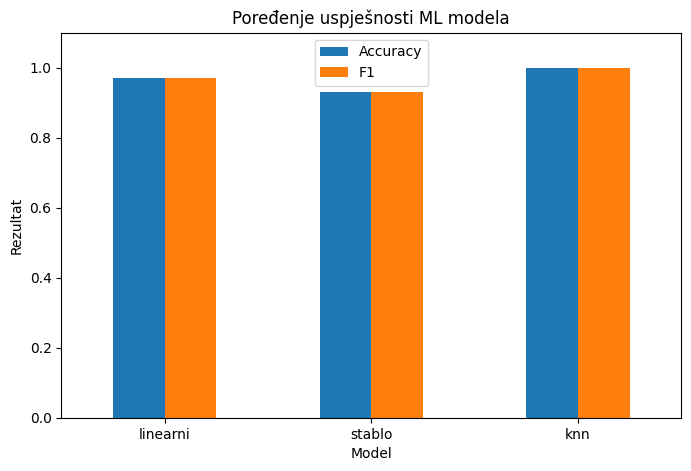

In [26]:

import matplotlib.pyplot as plt

tabela.plot(
    x="Model",
    y=["Accuracy", "F1"],
    kind="bar",
    figsize=(8, 5)
)

plt.title("Poređenje uspješnosti ML modela")
plt.xlabel("Model")
plt.ylabel("Rezultat")
plt.ylim(0, 1.1)
plt.xticks(rotation=0)
plt.legend()
plt.show()


In [27]:

import pytest

def test_kreiranje_modela():
    model = kreiraj_model("stablo")
    assert isinstance(model, DecisionTreeClassifier)


In [28]:

test_kreiranje_modela()
print("Prvi test je prosao!")


Prvi test je prosao!


In [29]:

def test_nepoznat_model():
    with pytest.raises(ValueError):
        kreiraj_model("nepoznat")


In [30]:

test_nepoznat_model()
print("Drugi test je prosao!")


Drugi test je prosao!


In [31]:

def test_tacnost():
    y_tacno = [0, 1, 2, 0]
    y_pred = [0, 1, 1, 0]

    rezultat = izracunaj_metriku("accuracy", y_tacno, y_pred)
    assert rezultat == 0.75


In [32]:

test_tacnost()
print("Treci test je prosao!")


Treci test je prosao!


In [33]:

def test_observer():
    trening = Treniranje()
    pratilac = PracenjeTreninga()

    trening.dodaj_pratioca(pratilac)

    assert len(trening.pratioci) == 1


In [34]:

test_observer()
print("Cetvrti test je prosao!")


Cetvrti test je prosao!


In [36]:

def test_eksperiment():
    eksperiment = Eksperiment()
    rezultat = eksperiment.pokreni()

    assert 0 <= rezultat <= 1


In [37]:

test_eksperiment()
print("Peti test je prosao!")


Zavrseno treniranje modela: DecisionTreeClassifier
Peti test je prosao!


In [39]:

def test_dekorator():
    @mjeri_vrijeme
    def saberi(a, b):
        return a + b

    rezultat = saberi(2, 3)
    assert rezultat == 5


In [40]:

test_dekorator()
print("Sesti test je prosao!")


Vrijeme izvrsavanja: 0.0 sekundi
Sesti test je prosao!


In [41]:

test_kreiranje_modela()
test_nepoznat_model()
test_tacnost()
test_observer()
test_eksperiment()
test_dekorator()

print("Svih 6 testova je proslo!")


Zavrseno treniranje modela: DecisionTreeClassifier
Vrijeme izvrsavanja: 0.0 sekundi
Svih 6 testova je proslo!


In [45]:

import inspect
from pathlib import Path

testovi = [
    test_kreiranje_modela,
    test_nepoznat_model,
    test_tacnost,
    test_observer,
    test_eksperiment,
    test_dekorator
]

kod = "import pytest\n"
kod += "from projekat import *\n\n"

for test in testovi:
    kod += inspect.getsource(test) + "\n\n"

Path("test_projekat.py").write_text(kod)


850

In [46]:

!python -m pytest test_projekat.py -v


============================= test session starts ==============================
platform linux -- Python 3.13.18, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content
plugins: platformdirs-4.14.3, anyio-4.16.0, typeguard-4.6.0, langsmith-0.14.17
collected 6 items                                                              

test_projekat.py::test_kreiranje_modela PASSED                           [ 16%]
test_projekat.py::test_nepoznat_model PASSED                             [ 33%]
test_projekat.py::test_tacnost PASSED                                    [ 50%]
test_projekat.py::test_observer PASSED                                   [ 66%]
test_projekat.py::test_eksperiment PASSED                                [ 83%]
test_projekat.py::test_dekorator PASSED                                  [100%]

============================== 6 passed in 2.24s ===============================


In [44]:

%%writefile projekat.py
import time
from functools import wraps

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score


iris = load_iris()


# Factory
def kreiraj_model(naziv):
    modeli = {
        "linearni": LogisticRegression(max_iter=200),
        "stablo": DecisionTreeClassifier(random_state=42),
        "knn": KNeighborsClassifier()
    }

    if naziv not in modeli:
        raise ValueError("Nepoznat model")

    return modeli[naziv]


# Strategy
def tacnost(y_tacno, y_pred):
    return accuracy_score(y_tacno, y_pred)


def f1_metrika(y_tacno, y_pred):
    return f1_score(y_tacno, y_pred, average="macro")


metrike = {
    "accuracy": tacnost,
    "f1": f1_metrika
}


def izracunaj_metriku(naziv, y_tacno, y_pred):
    return metrike[naziv](y_tacno, y_pred)


# Observer
class PracenjeTreninga:
    def kraj_treninga(self, naziv_modela):
        print("Zavrseno treniranje modela:", naziv_modela)


class Treniranje:
    def __init__(self):
        self.pratioci = []

    def dodaj_pratioca(self, pratilac):
        self.pratioci.append(pratilac)

    def treniraj(self, model, x, y):
        model.fit(x, y)

        for pratilac in self.pratioci:
            pratilac.kraj_treninga(type(model).__name__)

        return model


# Template Method
class Eksperiment:
    def pokreni(self):
        x_trening, x_test, y_trening, y_test = train_test_split(
            iris.data, iris.target,
            test_size=0.2,
            random_state=42,
            stratify=iris.target
        )

        model = self.napravi_model()

        trening = Treniranje()
        trening.dodaj_pratioca(PracenjeTreninga())
        trening.treniraj(model, x_trening, y_trening)

        predvidjanja = model.predict(x_test)
        rezultat = izracunaj_metriku("accuracy", y_test, predvidjanja)

        return rezultat

    def napravi_model(self):
        return kreiraj_model("stablo")


class KNNEksperiment(Eksperiment):
    def napravi_model(self):
        return kreiraj_model("knn")


# Decorator
def mjeri_vrijeme(funkcija):
    @wraps(funkcija)
    def nova_funkcija(*args, **kwargs):
        pocetak = time.time()
        rezultat = funkcija(*args, **kwargs)
        kraj = time.time()

        print("Vrijeme izvrsavanja:", round(kraj - pocetak, 4), "sekundi")
        return rezultat

    return nova_funkcija


class EksperimentSaVremenom(Eksperiment):
    @mjeri_vrijeme
    def pokreni(self):
        return super().pokreni()


Writing projekat.py


## Opis projekta

U okviru ovog mini projekta napravila sam jednostavan program za rad sa modelima mašinskog učenja, koristeći Iris skup podataka. Cilj zadatka bio je da primijenim projektne šablone koje smo obrađivali na predavanjima i da kroz praktičan primjer vidim kako oni funkcionišu.

Radila sam u Google Colabu, gdje sam postepeno dodavala kod, isprobavala različite modele i provjeravala njihove rezultate. Koristila sam tri modela: logističku regresiju, stablo odlučivanja i kNN.

## Primjena projektnih šablona

U programu sam koristila pet projektnih šablona.

**Factory** sam koristila za kreiranje različitih modela na osnovu njihovog naziva, tako da nije potrebno posebno pisati kod za svaki model.

**Strategy** omogućava izbor metrike za provjeru uspješnosti modela. Koristila sam Accuracy i F1 metrike.

**Observer** sam koristila za praćenje treniranja. Kada model završi treniranje, program ispisuje obavještenje.

**Template Method** određuje redosljed koraka eksperimenta, od pripreme podataka do treniranja i provjere rezultata. Na taj način sam mogla da koristim isti postupak za različite modele.

**Decorator** sam koristila za mjerenje vremena izvršavanja eksperimenta, bez potrebe da mijenjam osnovni postupak.

## Testiranje modela i rezultati

Iris skup podataka sadrži 150 primjera, koje sam podijelila na podatke za treniranje i testiranje. Za treniranje sam koristila 80%, a za testiranje preostalih 20%.

Nakon treniranja provjerila sam uspješnost sva tri modela pomoću Accuracy i F1 metrika. Najbolje rezultate na ovom testnom skupu imao je kNN model, zatim logistička regresija, dok je stablo odlučivanja imalo nešto slabiji rezultat.

Radi lakšeg poređenja, rezultate sam prikazala tabelom i grafikonom u Google Colabu.

## Pytest testovi

Za provjeru programa napisala sam šest pytest testova. Testirala sam kreiranje modela, ponašanje programa kada se unese nepoznat model, računanje tačnosti, dodavanje pratioca, pokretanje eksperimenta i rad dekoratora.
Prilikom prvog pokretanja testova pojavile su se greške jer pytest nije mogao da pronađe funkcije koje su bile definisane u Colabu. Problem sam riješila tako što sam glavni kod sačuvala u fajl 'projekat.py', a testove povezala sa tim fajlom.
Nakon ispravke ponovo sam pokrenula pytest i svih šest testova je uspješno prošlo.

Za pokretanje testova koristi se komanda:

`python -m pytest test_projekat.py -v`

## Korišćenje AI alata

Tokom izrade projekta koristila sam ChatGPT kao pomoć pri razumijevanju projektnih šablona i njihovoj primjeni u Pythonu. Posebno mi je koristio prilikom povezivanja različitih djelova programa i rješavanja problema sa testiranjem.
Neki od upita koje sam koristila odnosili su se na to kako napraviti jednostavan Factory za ML modele, kako primijeniti Strategy za izbor metrike, kako povezati Observer sa treniranjem i kako pokrenuti pytest testove u Google Colabu.
Prijedloge sam postepeno isprobavala i prilagođavala kod kako bi ostao što jednostavniji. Najvažnija ispravka bila je izdvajanje koda u poseban Python fajl, jer početni način pokretanja testova nije funkcionisao.

## Dijagram klasa

Mermaid dijagram prikazuje glavne klase korišćene u projektu, njihove metode i međusobne veze.


```mermaid
classDiagram
    class Eksperiment {
        +pokreni()
        +napravi_model()
    }

    class KNNEksperiment {
        +napravi_model()
    }

    class EksperimentSaVremenom {
        +pokreni()
    }

    class Treniranje {
        +dodaj_pratioca()
        +treniraj()
    }

    class PracenjeTreninga {
        +kraj_treninga()
    }

    Eksperiment <|-- KNNEksperiment
    Eksperiment <|-- EksperimentSaVremenom
    Eksperiment --> Treniranje
    Treniranje --> PracenjeTreninga
```


## Zaključak

Kroz ovaj projekat sam bolje razumjela kako se projektni šabloni mogu koristiti u jednom praktičnom primjeru. Takođe sam vježbala rad sa modelima mašinskog učenja, poređenje njihovih rezultata i pisanje testova.

Najviše pažnje posvetila sam tome da različiti djelovi programa budu povezani i da mogu pravilno da se testiraju.
